# Anomaly Detection and Finetuning

The goal here is to train a Isolation Forest anomaly detection model and finetune a 3B-parameter LLM in order to detect satellite system abnormalities and deliver a report for mission ops teams.
The models will be trained using the [OPSSAT-AD](https://zenodo.org/records/12588359) dataset.

In [8]:
# pip installs
!pip install -q -U transformers trl peft bitsandbytes accelerate datasets

import torch, transformers, trl, peft
print('torch', torch.__version__, '| transformers', transformers.__version__, '| trl', trl.__version__, '| peft', peft.__version__)
assert torch.cuda.is_available(), 'No GPU found. Runtime > Change runtime type > pick a GPU.'
print('GPU:', torch.cuda.get_device_name(0), '| free memory (GB):', round(torch.cuda.mem_get_info()[0] / 1e9, 1))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 110.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 15.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
torch 2.11.0+cu130 | transformers 5.18.0 | trl 1.15.0 | peft 0.21.1
GPU: Tesla T4 | free memory (GB): 15.5


### Carve out the train, validation, and test pool from the OPSSAT-AD dataset:

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("https://raw.githubusercontent.com/Tegh25/Satellite-Anomaly-Detector/refs/heads/main/model/dataset.csv")

test_df = df[df["train"] == 0]
train_pool = df[df["train"] == 1]

# Carve validation out of the train pool only, stratify so the ~20% anomaly rate
# is preserved in both slices, not skewed by chance
train_df, val_df = train_test_split(
    train_pool, test_size=0.15, stratify=train_pool["anomaly"], random_state=42
)

print(len(df), len(train_df), len(val_df), len(test_df))

2123 1354 240 529


In [ ]:
print(df['gaps_squared'].equals(df['duration']))
match_count = (df['gaps_squared'] == df['duration']).sum()
print(match_count)

False
234
mean: median=4.278e-06, 90th pct=0.3401, max=1.119
var: median=6.26e-10, 90th pct=0.1267, max=0.2725
std: median=2.502e-05, 90th pct=0.356, max=0.522
kurtosis: median=-1.303, 90th pct=-0.5877, max=31.2
skew: median=0.0108, 90th pct=0.9237, max=4.375
n_peaks: median=1, 90th pct=2, max=37
smooth10_n_peaks: median=1, 90th pct=1, max=5
smooth20_n_peaks: median=1, 90th pct=2, max=4
diff_peaks: median=4, 90th pct=54, max=240
diff2_peaks: median=14, 90th pct=65, max=256
diff_var: median=3.62e-11, 90th pct=0.002364, max=0.08506
diff2_var: median=1.063e-11, 90th pct=0.0005733, max=0.2457
gaps_squared: median=551, 90th pct=2000, max=2.075e+04
var_div_duration: median=3.866e-12, 90th pct=0.0003967, max=0.001687
var_div_len: median=1.604e-11, 90th pct=0.001607, max=0.008031


### Anomaly Detection Model

Two models will be compared:
1. Isolation Forest (unsupervised)
2. Random Forest (supervised)

**Worth comparing against a supervised baseline.** Isolation Forest is unsupervised and it never uses the `anomaly` labels during training, only for threshold tuning afterward. Given this dataset has anomaly labels, a supervised model will likely outperform it directly. The unsupervised approach is still justified, like it can catch novel anomaly types a supervised model was never trained on.

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, classification_report

feature_cols = [
    "mean", "var", "std", "kurtosis", "skew",
    "n_peaks", "smooth10_n_peaks", "smooth20_n_peaks",
    "diff_peaks", "diff2_peaks", "diff_var", "diff2_var",
    "gaps_squared", "var_div_duration", "var_div_len",
]

detector = IsolationForest(contamination=0.2, random_state=42)
detector.fit(train_df[feature_cols])

# Tune the decision threshold on validation instead of using the default
# the default threshold is derived purely from `contamination` at fit time,
# not from actually optimizing precision/recall on held-out data
val_scores = -detector.decision_function(val_df[feature_cols])
precision, recall, thresholds = precision_recall_curve(val_df["anomaly"], val_scores)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_threshold = thresholds[f1[:-1].argmax()]

# Testing
test_scores = -detector.decision_function(test_df[feature_cols])
test_preds = (test_scores >= best_threshold).astype(int)
print("Isolation Forest (unsupervised):")
print(classification_report(test_df["anomaly"], test_preds))

Isolation Forest (unsupervised):
              precision    recall  f1-score   support

           0       0.87      0.49      0.62       416
           1       0.28      0.74      0.41       113

    accuracy                           0.54       529
   macro avg       0.58      0.61      0.52       529
weighted avg       0.75      0.54      0.58       529



In [ ]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced")
clf.fit(train_df[feature_cols], train_df["anomaly"])

sup_preds = clf.predict(test_df[feature_cols])
print("Random Forest (supervised):")
print(classification_report(test_df["anomaly"], sup_preds))

Random Forest (supervised):
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       416
           1       0.95      0.83      0.89       113

    accuracy                           0.95       529
   macro avg       0.95      0.91      0.93       529
weighted avg       0.95      0.95      0.95       529



### Building the Finetuning Dataset

A frontier model will be used to generate high-quality draft reports for each labeled anomaly, conditioned on the real telemetry values and label. Later the smaller model will be trained on the high quality reports. This method is called distillation.

The below code block queries the backboard.io API and lists available OpenAI and Anthropic models.

In [ ]:
import requests
from google.colab import userdata

BACKBOARD_API_KEY = userdata.get("BACKBOARD_API_KEY")
headers = {"X-API-Key": BACKBOARD_API_KEY}

models = requests.get(
    "https://app.backboard.io/api/models/provider/openai",
    headers=headers,
    params={"model_type": "llm", "limit": 25}
).json()

for m in models["models"]:
    print(f"{m['provider']}/{m['name']} — "
          f"ctx: {m['context_limit']}, "
          f"thinking: {m.get('supports_thinking', False)}, "
          f"in: ${m.get('input_cost_per_1m_tokens', 'N/A')}/M, "
          f"out: ${m.get('output_cost_per_1m_tokens', 'N/A')}/M")

models = requests.get(
    "https://app.backboard.io/api/models/provider/anthropic",
    headers=headers,
    params={"model_type": "llm", "limit": 25}
).json()

for m in models["models"]:
    print(f"{m['provider']}/{m['name']} — "
          f"ctx: {m['context_limit']}, "
          f"thinking: {m.get('supports_thinking', False)}, "
          f"in: ${m.get('input_cost_per_1m_tokens', 'N/A')}/M, "
          f"out: ${m.get('output_cost_per_1m_tokens', 'N/A')}/M")


openai/gpt-4.1 — ctx: 1047576, thinking: False, in: $2.0/M, out: $8.0/M
openai/gpt-4.1-mini — ctx: 1047576, thinking: False, in: $0.4/M, out: $1.6/M
openai/gpt-4.1-nano — ctx: 1047576, thinking: False, in: $0.1/M, out: $0.4/M
openai/gpt-4o — ctx: 128000, thinking: False, in: $2.5/M, out: $10.0/M
openai/gpt-4o-mini — ctx: 128000, thinking: False, in: $0.15/M, out: $0.6/M
openai/gpt-4o-mini-transcribe — ctx: 0, thinking: False, in: $1.25/M, out: $5.0/M
openai/gpt-4o-transcribe — ctx: 0, thinking: False, in: $2.5/M, out: $10.0/M
openai/gpt-4o-transcribe-diarize — ctx: 0, thinking: False, in: $2.5/M, out: $10.0/M
openai/gpt-5 — ctx: 400000, thinking: True, in: $1.25/M, out: $10.0/M
openai/gpt-5-chat-latest — ctx: 128000, thinking: False, in: $1.25/M, out: $10.0/M
openai/gpt-5-codex — ctx: 400000, thinking: True, in: $1.25/M, out: $10.0/M
openai/gpt-5-mini — ctx: 400000, thinking: True, in: $0.25/M, out: $2.0/M
openai/gpt-5-nano — ctx: 400000, thinking: True, in: $0.05/M, out: $0.4/M
openai

Reports will saved in a Google Drive file incrementally so that they are not lost in the case of an interruption.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

TEST_OUTPUT_PATH = '/content/drive/MyDrive/satellite-anomaly-project/test_reports.jsonl'

import os
os.makedirs(os.path.dirname(TEST_OUTPUT_PATH), exist_ok=True)

Mounted at /content/drive


#### Testing the Frontier Model's Reports

Generating effective reports for anomalous/non-anomalous rows is dependant on both data analysis and good prompt engineering. Below is a test that generate 10 reports on 5 anomalous and 5 nominal rows, the prompt and its included data has went through multiple iterations to ensure that the LLM output is effective. Sonnet 5 was chosen due to its quality and cost.

The report generation for all rows of the dataset were done locally using a python script, not in this Colab file.

In [ ]:
import json
import requests
from google.colab import userdata

# Keys and config
BACKBOARD_API_KEY = userdata.get("BACKBOARD_API_KEY")
BACKBOARD_API_URL = "https://app.backboard.io/api"
BACKBOARD_LLM_PROVIDER = "anthropic"
BACKBOARD_MODEL_NAME = "claude-sonnet-5"

def load_completed_ids(path):
    completed = set()
    if os.path.exists(path):
        with open(path, 'r') as f:
            for line in f:
                completed.add(json.loads(line)['segment'])
    return completed

def append_result(path, segment_id, report):
    with open(path, 'a') as f:
        f.write(json.dumps({"segment": segment_id, "report": report}) + "\n")

completed_ids = load_completed_ids(TEST_OUTPUT_PATH)
print(f"Already done: {len(completed_ids)} rows")

## Test of append result function ##
# report = "Segment statistics are consistent with nominal channel behavior: near-zero mean with very low variance/std dev indicates a stable, low-amplitude signal with no significant excursions. The negative kurtosis (-1.275) suggests a flatter-than-Gaussian distribution rather than spiky outliers, and low skew confirms symmetry — no evidence of transient spikes or sudden jumps. Peak counts remain consistent (1) across raw and smoothed views, and while sampling gap irregularity (1150) is noted, it does not manifest in derivative statistics as anomalous discontinuities, suggesting it's a minor timing artifact rather than a data-loss event. **No action required** — continue routine monitoring."
# append_result(TEST_OUTPUT_PATH, 789, report)

if not BACKBOARD_API_KEY:
    raise ValueError("Set the BACKBOARD_API_KEY environment variable before running this notebook cell.")

feature_cols = [
    "mean", "var", "std", "kurtosis", "skew",
    "n_peaks", "smooth10_n_peaks", "smooth20_n_peaks",
    "diff_peaks", "diff2_peaks", "diff_var", "diff2_var",
    "gaps_squared", "var_div_duration", "var_div_len",
]

# Compute reference statistics from train_df
reference_stats = train_df[feature_cols].describe(percentiles=[0.5, 0.9]).loc[["50%", "90%", "max"]]

def format_reference_line(col):
    return f"{col}: median={reference_stats.loc['50%', col]:.4g}, 90th pct={reference_stats.loc['90%', col]:.4g}, max={reference_stats.loc['max', col]:.4g}"

reference_block = "\n".join(format_reference_line(c) for c in feature_cols)

def generate_report(row):
    prompt = f"""You are a spacecraft operations engineer reviewing a flagged telemetry segment.
Note: these are pre-computed statistical features of the segment, not raw sensor values —
reason about what they imply rather than treating them as physical readings.

For internal calibration only — DO NOT mention these numbers, percentiles, or "the dataset" in your
final report. Use them only to judge whether a statistic for this segment is genuinely unusual:
{reference_block}

Write the report as a standalone assessment of this segment, in the same plain language a mission-ops
engineer would use looking at one live reading with no visibility into a historical dataset. Do not
reference medians, percentiles, "typical values," or any dataset-level comparison directly — describe
what's unusual in physical/operational terms instead (e.g. "unusually high for this channel," not
"90th-percentile value").

Channel: {row['channel']}
Segment length: {row['len']} samples over {row['duration']} time units
Mean: {row['mean']:.6g}, Std dev: {row['std']:.6g}, Variance: {row['var']:.6g}
Kurtosis: {row['kurtosis']:.3f}, Skew: {row['skew']:.3f}  (distribution shape — spiky/flat, lopsided/symmetric)
Peak count (raw / smoothed-10 / smoothed-20): {row['n_peaks']} / {row['smooth10_n_peaks']} / {row['smooth20_n_peaks']}
Derivative peak count (1st / 2nd diff): {row['diff_peaks']} / {row['diff2_peaks']}
Derivative variance (1st / 2nd diff): {row['diff_var']:.6g} / {row['diff2_var']:.6g}
Sampling gap irregularity: {row['gaps_squared']}
Label: {"ANOMALY" if row['anomaly'] == 1 else "NOMINAL"}

First, identify which of the provided statistics are actually the most unusual or informative
for THIS segment specifically, do not default to any one feature (e.g. sampling gap irregularity)
unless it is genuinely the standout signal here. Different segments may be explained by different
features: distribution shape, peak structure, derivative behavior, or sampling irregularity can each
be the dominant story depending on the row.

Write a concise mission-ops report (3-4 sentences) covering:
- Which specific statistic(s) actually drive your assessment for this segment, and why
- The likely cause, reasoned from those specific statistics (not a generic category)
- Suggested next step for the ops team, specific to that likely cause

(Remember: describe what's unusual in plain operational terms, with no mention of percentiles,
medians, or dataset-level comparisons.)

If NOMINAL, write a brief confirmation grounded in the specific statistics, not a generic template.

Respond with plain prose only, no headers or markdown formatting. No em dashes."""

    response = requests.post(
        f"{BACKBOARD_API_URL}/threads/messages",
        headers={"X-API-Key": BACKBOARD_API_KEY},
        json={
            "content": prompt,
            "llm_provider": BACKBOARD_LLM_PROVIDER,
            "model_name": BACKBOARD_MODEL_NAME,
            "stream": False,
            "memory": "off",
            "system_prompt": "You are a spacecraft operations engineer. Provide concise, evidence-based assessments for telemetry anomalies.",
        },
        timeout=120,
    )
    response.raise_for_status()
    payload = response.json()
    return payload.get("content") or payload.get("message") or ""

anomaly_sample = df[df['anomaly'] == 1].sample(n=5, random_state=42)
nominal_sample = df[df['anomaly'] == 0].sample(n=5, random_state=42)
stratified_sample = pd.concat([anomaly_sample, nominal_sample]).sample(frac=1, random_state=42).reset_index(drop=True)

print(stratified_sample[['segment', 'channel', 'anomaly']])

for _, row in stratified_sample.iterrows():
    if row['segment'] in completed_ids:
        continue  # skip rows already generated on a prior run
    try:
        report = generate_report(row)
        append_result(TEST_OUTPUT_PATH, row['segment'], report)
    except Exception as e:
        print(f"Row {row['segment']} failed: {e}")
        continue  # move on instead of crashing the whole loop

Already done: 0 rows
   segment   channel  anomaly
0     1808  CADC0872        0
1      235  CADC0892        1
2     1280  CADC0873        0
3     1183  CADC0873        1
4     1022  CADC0873        0
5      293  CADC0874        1
6     1035  CADC0873        0
7     1617  CADC0888        1
8      945  CADC0892        1
9     2055  CADC0872        0


### Satellite telemetry anomaly reports: format the data and fine-tune with QLoRA

`SMOKE_TEST = True`: It trains for 10 steps only, which proves the whole pipeline works and tells you how long the real run will take. Then set it to `False` and rerun from the config cell for the real run.

Files this notebook reads: `dataset.csv` and `reports.jsonl` (must be saved in Google Drive). Files it writes (into a `finetune/` subfolder): `train.jsonl`, `val.jsonl`, `test.jsonl`, checkpoints, the LoRA adapter, and a loss-curve image.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_DIR = Path('/content/drive/MyDrive/satellite-anomaly-project/')
DATASET_CSV = PROJECT_DIR / 'dataset.csv'
REPORTS_JSONL = PROJECT_DIR / 'reports.jsonl'
OUT_DIR = PROJECT_DIR / 'finetune'
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Apache 2.0 licensed non-thinking instruct model, 4B parameters.
MODEL_NAME = 'Qwen/Qwen3-4B-Instruct-2507'

SMOKE_TEST = False   # True = 10 training steps only. Set to False for real run.

# Segments to be skipped
EXCLUDE_SEGMENTS = []
SEED = 42

for p in (DATASET_CSV, REPORTS_JSONL):
    assert p.exists(), f'Missing {p}. Fix the path above.'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Merge the reports with the dataset, rebuild the split, run a quality gate

The reports file only has `segment` and `report`. We join it to the dataset on `segment`, then rebuild the exact train/val/test split used when the reports were generated (the provided `train` column, with 15% of the train pool held out for validation). The reference statistics in the generation prompt were computed from that train split, so keeping it identical matters.

The quality gate drops any report that is empty, or contains an em dash, markdown, or percentile/median/dataset language.

In [11]:
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(DATASET_CSV)
df['segment'] = df['segment'].astype(int)

with open(REPORTS_JSONL, encoding='utf-8') as f:
    rep = pd.DataFrame([json.loads(line) for line in f if line.strip()])
rep['segment'] = pd.to_numeric(rep['segment']).astype(int)
print(f'dataset rows: {len(df)} | report lines: {len(rep)} | unique segments with a report: {rep["segment"].nunique()}')
rep = rep.drop_duplicates('segment', keep='last')

data = df.merge(rep[['segment', 'report']], on='segment', how='left')

# Same split as the generation script (stratify on anomaly, same seed)
pool = data[data['train'] == 1]
train_idx, val_idx = train_test_split(
    pool.index, test_size=0.15, stratify=pool['anomaly'], random_state=SEED
)
data['split'] = 'test'
data.loc[train_idx, 'split'] = 'train'
data.loc[val_idx, 'split'] = 'val'

# Flags. Hard flags drop the row from training. The soft flag is only counted.
r = data['report'].fillna('')
data['flag_empty'] = r.str.strip() == ''
data['flag_em_dash'] = r.str.contains('\u2014', regex=False)
data['flag_markdown'] = r.str.contains(r'(?m)\*\*|^#', regex=True)
data['flag_excluded'] = data['segment'].isin(EXCLUDE_SEGMENTS)
data['soft_dataset_language'] = r.str.contains(r'percentile|median|dataset', case=False, regex=True)
data['drop'] = data[['flag_empty', 'flag_em_dash', 'flag_markdown', 'flag_excluded']].any(axis=1)

# Save everything (nothing removed) before filtering. The original reports.jsonl is never touched.
merged_path = OUT_DIR / 'merged_reports.jsonl'
data.to_json(merged_path, orient='records', lines=True, force_ascii=False)
print('saved merged file:', merged_path)

print(data.groupby('split').agg(
    rows=('segment', 'size'),
    dropped=('drop', 'sum'),
    missing_report=('flag_empty', 'sum'),
    em_dash=('flag_em_dash', 'sum'),
    markdown=('flag_markdown', 'sum'),
    excluded=('flag_excluded', 'sum'),
    dataset_language_kept=('soft_dataset_language', 'sum'),
).to_string())
missing = data.loc[data['flag_empty'] & ~data['flag_excluded'], 'segment'].tolist()
if missing:
    print(f'\nWARNING: {len(missing)} segments have no report. First few: {missing[:15]}')

kept = data[~data['drop']]
train_part = kept[kept['split'] == 'train']
val_part = kept[kept['split'] == 'val']
test_part = kept[kept['split'] == 'test']
print(f'\nkept -> train {len(train_part)}, val {len(val_part)}, test {len(test_part)}')
print('anomaly rate (train/val/test):', round(train_part['anomaly'].mean(), 3), round(val_part['anomaly'].mean(), 3), round(test_part['anomaly'].mean(), 3))
print(train_part['report'].str.split().str.len().describe().round(0))

dataset rows: 2123 | report lines: 2123 | unique segments with a report: 2123
saved merged file: /content/drive/MyDrive/satellite-anomaly-project/finetune/merged_reports.jsonl
       rows  dropped  missing_report  em_dash  markdown  excluded  dataset_language_kept
split                                                                                   
test    529        9               0        9         0         0                      0
train  1354       22               0       22         0         0                      0
val     240        2               0        2         0         0                      0

kept -> train 1332, val 238, test 520
anomaly rate (train/val/test): 0.197 0.197 0.21
count    1332.0
mean      156.0
std        22.0
min       100.0
25%       140.0
50%       155.0
75%       169.0
max       238.0
Name: report, dtype: float64


### Build the instruction-tuning pairs

Each example has a **prompt** (system message plus the telemetry features and label) and a **completion** (the report written by the teacher model).

In [12]:
SYSTEM_PROMPT = (
    'You are a spacecraft operations engineer. You receive pre-computed statistical features of one flagged '
    'telemetry segment (not raw sensor values) plus its label. Write a concise, evidence-based mission-ops '
    'assessment in plain prose: which statistics drive your assessment, the likely cause, and the next step '
    'for the ops team.'
)

def build_user_message(row):
    return (
        f"Channel: {row['channel']}\n"
        f"Segment length: {row['len']} samples over {row['duration']} time units\n"
        f"Mean: {row['mean']:.6g}, Std dev: {row['std']:.6g}, Variance: {row['var']:.6g}\n"
        f"Kurtosis: {row['kurtosis']:.3f}, Skew: {row['skew']:.3f}\n"
        f"Peak count (raw / smoothed-10 / smoothed-20): {row['n_peaks']} / {row['smooth10_n_peaks']} / {row['smooth20_n_peaks']}\n"
        f"Derivative peak count (1st / 2nd diff): {row['diff_peaks']} / {row['diff2_peaks']}\n"
        f"Derivative variance (1st / 2nd diff): {row['diff_var']:.6g} / {row['diff2_var']:.6g}\n"
        f"Sampling gap irregularity: {row['gaps_squared']}\n"
        f"Label: {'ANOMALY' if row['anomaly'] == 1 else 'NOMINAL'}"
    )

def to_record(row):
    return {
        'segment': int(row['segment']),
        'anomaly': int(row['anomaly']),
        'prompt': [
            {'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': build_user_message(row)},
        ],
        'completion': [{'role': 'assistant', 'content': row['report'].strip()}],
    }

def to_records(part):
    return [to_record(r) for _, r in part.iterrows()]

train_recs, val_recs, test_recs = map(to_records, (train_part, val_part, test_part))

for name, recs in [('train', train_recs), ('val', val_recs), ('test', test_recs)]:
    with open(OUT_DIR / f'{name}.jsonl', 'w', encoding='utf-8') as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
    print(f'wrote {name}.jsonl ({len(recs)} examples)')

ex = train_recs[0]
print('\n' + ex['prompt'][1]['content'])
print('\n--- COMPLETION ---')
print(ex['completion'][0]['content'])

wrote train.jsonl (1332 examples)
wrote val.jsonl (238 examples)
wrote test.jsonl (520 examples)

Channel: CADC0872
Segment length: 280 samples over 279 time units
Mean: 8.53314e-07, Std dev: 1.8693e-05, Variance: 3.49428e-10
Kurtosis: 0.631, Skew: 0.552
Peak count (raw / smoothed-10 / smoothed-20): 4 / 3 / 2
Derivative peak count (1st / 2nd diff): 4 / 6
Derivative variance (1st / 2nd diff): 1.27118e-10 / 2.96067e-10
Sampling gap irregularity: 309
Label: ANOMALY

--- COMPLETION ---
Looking at this segment, nothing in the amplitude statistics stands out: the mean, variance, and standard deviation are all extremely small and unremarkable, and the kurtosis (0.631) and skew (0.552) describe a mild, near-symmetric distribution with no sharp spiking behavior. Peak counts are also modest and consistent across raw and smoothed versions (4 down to 2), meaning there's no evidence of noisy transients being smoothed away. The one figure that clearly breaks pattern here is the sampling gap irregula

### Check token lengths

Any example longer than `max_length` gets truncated, which would cut off the end of a report. We measure the real lengths and set `MAX_LEN` just above the longest example.

In [13]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def n_tokens(rec):
    text = tok.apply_chat_template(rec['prompt'] + rec['completion'], tokenize=False)
    return len(tok(text)['input_ids'])

lens = np.array([n_tokens(r) for r in train_recs])
print(f'tokens per example: median {int(np.median(lens))}, 99th percentile {int(np.percentile(lens, 99))}, max {int(lens.max())}')
MAX_LEN = int(np.ceil((lens.max() + 16) / 128) * 128)
print('MAX_LEN =', MAX_LEN)

tokens per example: median 480, 99th percentile 554, max 582
MAX_LEN = 640


### Load the base model in 4-bit and attach LoRA adapters (QLoRA)

- **Quantization:** the frozen base weights are stored in 4-bit (NF4), which cuts memory about 4x with a small quality cost.
- **LoRA:** instead of updating billions of weights, we train small low-rank adapter matrices attached to each layer. `r=16` is the adapter rank (capacity), and `lora_alpha=32` scales how strongly the adapters influence the output. Only the adapters train, usually well under 1% of the parameters.
- **Target modules:** adapters go on all the attention and MLP projection layers. This is the standard QLoRA choice and gives the model more room to learn a writing style than attention-only adapters.
- **fp16 vs bf16:** a T4 GPU cannot do bf16 properly, so the notebook trains in fp16 there and switches to bf16 automatically on newer GPUs (L4, A100). If the loss ever becomes `nan` on a T4, use an L4 or A100 runtime instead.

In [14]:
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, prepare_model_for_kbit_training

USE_BF16 = torch.cuda.get_device_capability(0)[0] >= 8   # Ampere or newer
compute_dtype = torch.bfloat16 if USE_BF16 else torch.float16
print('compute dtype:', compute_dtype)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=compute_dtype,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    quantization_config=bnb_config,
    device_map={'': 0},
    dtype=compute_dtype,
)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias='none',
    task_type='CAUSAL_LM',
    target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'],
)
print('GPU memory used (GB):', round(torch.cuda.memory_allocated() / 1e9, 1))

compute dtype: torch.float16


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

GPU memory used (GB): 10.9


### Train

In smoke-test mode this cell prints an estimate of the full run time. It slightly overestimates, because the 10-step run includes one validation pass.

In [15]:
from datasets import Dataset
from trl import SFTConfig, SFTTrainer

def to_ds(recs):
    return Dataset.from_list([{'prompt': r['prompt'], 'completion': r['completion']} for r in recs])

train_ds, val_ds = to_ds(train_recs), to_ds(val_recs)

ckpt_dir = OUT_DIR / ('checkpoints_smoke' if SMOKE_TEST else 'checkpoints')

args = SFTConfig(
    output_dir=str(ckpt_dir),
    num_train_epochs=3,
    max_steps=10 if SMOKE_TEST else -1,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    lr_scheduler_type='cosine',
    warmup_steps=8,
    max_length=MAX_LEN,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant': False},
    bf16=USE_BF16,
    fp16=not USE_BF16,
    logging_steps=5,
    eval_strategy='steps',
    eval_steps=10 if SMOKE_TEST else 50,
    save_strategy='steps',
    save_steps=10 if SMOKE_TEST else 50,
    save_total_limit=2,
    load_best_model_at_end=not SMOKE_TEST,
    metric_for_best_model='eval_loss',
    greater_is_better=False,
    report_to='none',
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tok,
    peft_config=lora_config,
)
trainer.model.print_trainable_parameters()

last_ckpt = None
found = sorted(ckpt_dir.glob('checkpoint-*'), key=lambda p: int(p.name.split('-')[1]))
if found and not SMOKE_TEST:
    last_ckpt = str(found[-1])
    print('Resuming from', last_ckpt)

trainable = lambda: {p.dtype for p in trainer.model.parameters() if p.requires_grad}
print('trainable dtypes before:', trainable())

if not USE_BF16:   # fp16 mixed precision needs fp32 trainable weights
    for p in trainer.model.parameters():
        if p.requires_grad and p.dtype != torch.float32:
            p.data = p.data.to(torch.float32)

print('trainable dtypes after:', trainable())

result = trainer.train(resume_from_checkpoint=last_ckpt)

if SMOKE_TEST:
    per_step = result.metrics['train_runtime'] / 10
    total_steps = int(np.ceil(len(train_ds) / 16)) * 3
    print(f'\n~{per_step:.0f} s/step. Full run is {total_steps} steps, roughly {per_step * total_steps / 3600:.1f} hours.')
    print('Smoke test passed if you got here without errors. Set SMOKE_TEST = False, then rerun from the config cell.')

Tokenizing train dataset:   0%|          | 0/1332 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1332 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1332 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1332 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/238 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/238 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/238 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/238 [00:00<?, ? examples/s]

trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145
trainable dtypes before: {torch.bfloat16}
trainable dtypes after: {torch.float32}


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
50,0.870639,0.876342,0.839003,0.742263,383939.000000
100,0.749608,0.779167,0.713387,0.764600,765403.000000
150,0.685577,0.733709,0.687495,0.775005,1150697.000000
200,0.581769,0.718199,0.603548,0.779874,1530422.000000
250,0.590229,0.711737,0.593296,0.782455,1915819.000000
252,0.590229,0.711753,0.593277,0.782454,1925304.000000


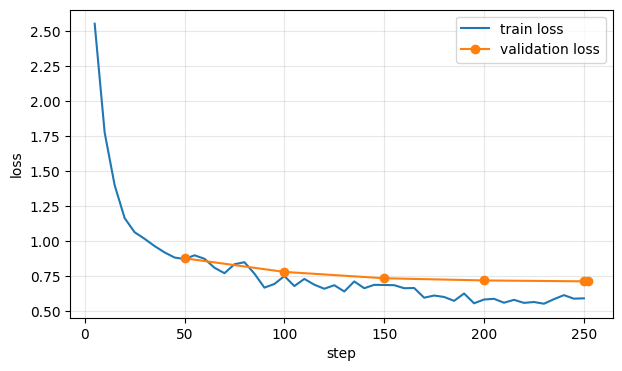

saved adapter to /content/drive/MyDrive/satellite-anomaly-project/finetune/adapter_final


In [16]:
import matplotlib.pyplot as plt

log = trainer.state.log_history
tr = [(l['step'], l['loss']) for l in log if 'loss' in l]
ev = [(l['step'], l['eval_loss']) for l in log if 'eval_loss' in l]

plt.figure(figsize=(7, 4))
if tr: plt.plot(*zip(*tr), label='train loss')
if ev: plt.plot(*zip(*ev), marker='o', label='validation loss')
plt.xlabel('step'); plt.ylabel('loss'); plt.legend(); plt.grid(alpha=0.3)
tag = 'smoke' if SMOKE_TEST else 'final'
plt.savefig(OUT_DIR / f'loss_curve_{tag}.png', dpi=150, bbox_inches='tight')
plt.show()

trainer.save_model(str(OUT_DIR / f'adapter_{tag}'))
tok.save_pretrained(str(OUT_DIR / f'adapter_{tag}'))
print('saved adapter to', OUT_DIR / f'adapter_{tag}')

In [17]:
model_ft = trainer.model
model_ft.eval()

def generate(rec, max_new_tokens=450):
    text = tok.apply_chat_template(rec['prompt'], tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors='pt').to(model_ft.device)
    with torch.no_grad():
        out = model_ft.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, use_cache=True)
    return tok.decode(out[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)

picks = [r for r in test_recs if r['anomaly'] == 1][:2] + [r for r in test_recs if r['anomaly'] == 0][:1]
for rec in picks:
    print('=' * 80)
    print('segment', rec['segment'], '|', rec['prompt'][1]['content'].splitlines()[-1])
    print('\n--- FINE-TUNED MODEL ---')
    print(generate(rec))
    print('\n--- TEACHER REPORT ---')
    print(rec['completion'][0]['content'])

segment 13 | Label: ANOMALY

--- FINE-TUNED MODEL ---
This segment's amplitude statistics (mean, std, variance) are all extremely small and unremarkable, and the shape descriptors (kurtosis -0.813, skew 0.390) show a flat, mildly lopsided but otherwise quiet distribution with no spiky or heavy-tailed behavior. Peak counts are minimal and consistent across raw and smoothed versions (1/1/1), and derivative variances are vanishingly small, indicating no abrupt jumps or oscillatory structure in the signal itself. The one clear outlier here is the sampling gap irregularity value of 229, essentially on the same order as the segment length itself, which points to a timing or acquisition problem rather than a physical excursion in the measured quantity. This pattern is consistent with dropped samples, buffering delays, or a telemetry timing fault rather than a real sensor event, so the recommended next step is to check the onboard data handling or downlink timestamps for this channel around th